# Linear buckling analysis of a plate

A simply supported plate under uniaxial compression, in two variants:

1. with `Quad4R` elements, the prestress coming from the linear static
   solution of the applied edge loads, through `update_probe_ue` and
   `update_KG`;
2. with `Quad4` elements and a constant membrane stress state given directly
   to each element with `update_KG_given_stress`.

The eigenvalue problem is solved with `pyfe3d.solver.linear_buckling`, see
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst) and
[Eigenvalue solvers and their verification](../eigenvalue_solvers.rst). The
critical loads are compared with the exact buckling load of Leissa (1969).
The elements are described in
[Quad4R: one-point integration and hourglass control](../shell_quad4r.rst)
and [Quad4: assumed transverse shear strains (MITC4)](../shell_quad4.rst);
the full references are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from numpy import isclose
from scipy.sparse import coo_matrix

from pyfe3d import (DOF, DOUBLE, INT, Quad4R, Quad4RData, Quad4RProbe, Quad4,
                    Quad4Data, Quad4Probe)
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import linear_buckling, solve

## The reference value

Leissa (1969, Sec. 10.2.1, p. 277) gives the buckling load of the plate with
all edges simply supported under a uniform $N_{xx}$, Eq. (10.46), as the load
at which the frequency of his Eq. (10.44) vanishes. Minimised over the number
$m$ of half-waves along $x$, it reads

$$
N_{xx,cr} = -k_c \frac{\pi^2 D}{b^2}, \qquad
k_c = \left(\frac{m b}{a} + \frac{a}{m b}\right)^2, \qquad
D = \frac{E h^3}{12 (1 - \nu^2)}
$$

The resultant on the loaded edge of width $b$ is $P_{cr} = N_{xx,cr} b$:

In [2]:
def leissa(a, b, h, E, nu):
    ms = np.arange(1, 21)
    kcs = (ms*b/a + a/(ms*b))**2
    kc = kcs.min()
    D = E*h**3/(12*(1 - nu**2))
    return kc, ms[np.argmin(kcs)], -kc*np.pi**2*D/b**2*b

## 1. Quad4R, prestress from a linear static solution

The plate has $a = 2$ m along $x$, $b = 0.5$ m, $h = 0.003$ m, $E = 203$ GPa
and $\nu = 0.33$. For $a/b = 4$ the minimum is $k_c = 4$ at $m = 4$:

In [3]:
a, b, h = 2.0, 0.5, 0.003
E, nu = 203.e9, 0.33
kc, m_cr, P_ref = leissa(a, b, h, E, nu)
print('k_c = %.4f, m = %d, P_cr = %.2f N' % (kc, m_cr, P_ref))

k_c = 4.0000, m = 4, P_cr = -40470.81 N


The function below builds the mesh with `refinement*31` by `refinement*15`
nodes (rounded up to odd numbers, so that a node sits at the middle of each
edge), with $w = 0$ on the four edges; the in-plane rigid-body modes are
removed by holding $u$ at the middle of the edges $y = 0, b$ and $v$ at the
middle of the edges $x = 0, a$. Uniform compressive forces of 1000 N in total
act on the edges $x = 0$ and $x = a$, lumped to the edge nodes (half the
nodal force at the corners), and balance each other.

The steps of the buckling analysis are:

1. assemble $\boldsymbol{K}_{C0}$ and solve the linear static problem of the
   reference load, $\boldsymbol{u}_0$;
2. give $\boldsymbol{u}_0$ to each element with `update_probe_ue`: `update_KG`
   then computes the membrane stress resultants of the element and its
   geometric stiffness matrix $\boldsymbol{K}_G$;
3. solve $(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G) \boldsymbol{u} =
   \boldsymbol{0}$ for the lowest load multipliers $\lambda$ with
   `linear_buckling`, which equilibrates the diagonal, estimates the shift of
   the Cayley transformation and verifies that no lower multiplier was missed.

The critical load is $\lambda_1$ times the reference load:

In [4]:
def quad4r_plate(refinement, num_eigvalues=4):
    data = Quad4RData()
    probe = Quad4RProbe()
    nx = refinement*31
    ny = refinement*15
    nx += 1 - nx % 2
    ny += 1 - ny % 2
    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    ncoords_flatten = ncoords.flatten()
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*nx*ny

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    prop = isotropic_plate(thickness=h, E=E, nu=nu)
    quads = []
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4R(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.init_k_KG = k*data.KG_SPARSE_SIZE
        quad.K6ROT = 100.
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quads.append(quad)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    bk = np.zeros(N, dtype=bool)
    bk[2::DOF] = isclose(x, 0.) | isclose(x, a) | isclose(y, 0) | isclose(y, b)
    bk[0::DOF] = isclose(x, a/2.) & (isclose(y, 0.) | isclose(y, b))
    bk[1::DOF] = isclose(y, b/2.) & (isclose(x, 0.) | isclose(x, a))
    bu = ~bk

    # compressive edge loads, 1000 N in total on each loaded edge
    ftotal = -1000.
    fext = np.zeros(N)
    corner = isclose(y, 0) | isclose(y, b)
    for xedge, sign in [(0., -1.), (a, 1.)]:
        edge = isclose(x, xedge)
        fext[0::DOF][edge & ~corner] = sign*ftotal/(ny - 1)
        fext[0::DOF][edge & corner] = sign*ftotal/(ny - 1)/2

    u0 = np.zeros(N)
    u0[bu] = solve(KC0[bu, :][:, bu], fext[bu])

    for quad in quads:
        quad.update_probe_ue(u0)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KG(KGr, KGc, KGv, prop)
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()

    eigvals, eigvecsu = linear_buckling(KC0[bu, :][:, bu], KG[bu, :][:, bu],
                                        num_eigvalues=num_eigvalues, tol=1e-9)
    eigvecs = np.zeros((N, num_eigvalues))
    eigvecs[bu] = eigvecsu
    return dict(num_elements=(nx - 1, ny - 1), P_cr=eigvals[0]*ftotal,
                eigvals=eigvals, eigvecs=eigvecs, xmesh=xmesh, ymesh=ymesh,
                nx=nx, ny=ny)

Three meshes, with the physical stabilisation of the bending and of the
transverse shear of Belytschko and Leviathan (1994) that `Quad4R` uses:

In [5]:
print('%-9s %14s %14s %11s' % ('elements', 'P_cr (N)', 'Leissa (N)',
                               'rel. diff.'))
for refinement in [1, 2, 3]:
    res = quad4r_plate(refinement)
    print('%-9s %14.2f %14.2f %11.2e' % ('%dx%d' % res['num_elements'],
          res['P_cr'], P_ref, res['P_cr']/P_ref - 1))
print('load multipliers of the finest mesh:', res['eigvals'])

elements        P_cr (N)     Leissa (N)  rel. diff.


30x14          -41058.16      -40470.81    1.45e-02


62x30          -40572.79      -40470.81    2.52e-03


92x44          -40490.97      -40470.81    4.98e-04
load multipliers of the finest mesh: [40.49097422 42.5815938  43.92275118 47.64043236]


The four lowest buckling modes of the finest mesh, contours of $w$: the first
one has the $m = 4$ half-waves of the reference. The next multipliers are
close to the first one, since $k_c$ changes little with $m$ for a long plate:

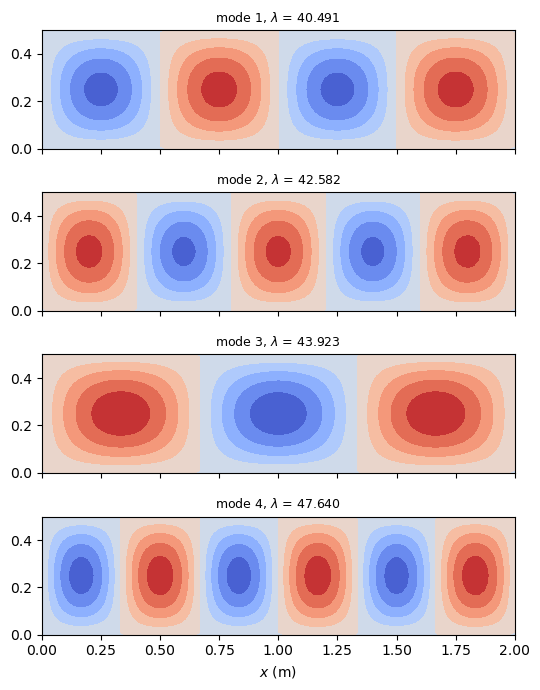

In [6]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(8, 7))
for i, ax in enumerate(axs):
    ax.set_aspect('equal')
    wmode = res['eigvecs'][2::DOF, i].reshape(res['nx'], res['ny']).T
    ax.contourf(res['xmesh'], res['ymesh'], wmode, levels=10, cmap='coolwarm')
    ax.set_title(r'mode %d, $\lambda$ = %.3f' % (i + 1, res['eigvals'][i]),
                 fontsize=9)
axs[-1].set_xlabel('$x$ (m)')
plt.tight_layout()
plt.show()

## 2. Quad4, given membrane stress

When the prestress is known, as here the uniform $N_{xx}$, no static solution
is needed: `update_KG_given_stress(Nxx, Nyy, Nxy, ...)` builds
$\boldsymbol{K}_G$ of each element directly from the given stress resultants.
The plate has $a = 2$ m, $b = 0.5$ m, $h = 0.002$ m, $E = 203$ GPa and $\nu =
0.33$, all the translations of the edge nodes are held, and $N_{xx} = -1$
N/m, so that the load multiplier is the critical $N_{xx}$ in N/m. With $b/h =
250$ the Mindlin plate buckles 0.01 % below the Kirchhoff reference, so the
reference also applies to the element:

In [7]:
def quad4_plate_given_stress(nx, ny, a=2.0, b=0.5, h=0.002, E=203.e9,
                             nu=0.33, Nxx=-1.):
    prop = isotropic_plate(E=E, nu=nu, thickness=h)
    data = Quad4Data()
    probe = Quad4Probe()
    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    ncoords_flatten = ncoords.flatten()
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*ncoords.shape[0]
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.init_k_KG = k*data.KG_SPARSE_SIZE
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_KG_given_stress(Nxx, 0, 0, KGr, KGc, KGv)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()
    bk = np.zeros(N, dtype=bool)
    edge = isclose(x, 0.) | isclose(x, a) | isclose(y, 0.) | isclose(y, b)
    bk[0::DOF] = edge
    bk[1::DOF] = edge
    bk[2::DOF] = edge
    bu = ~bk
    return KC0[bu, :][:, bu], KG[bu, :][:, bu]

In [8]:
Nxx = -1.
kc2, m2, P_ref2 = leissa(2.0, 0.5, 0.002, 203.e9, 0.33)
print('Leissa: k_c = %.4f, m = %d, N_xx,cr = %.3f N/m'
      % (kc2, m2, P_ref2/0.5))
print('%-9s %16s %16s %11s %18s' % ('elements', 'N_xx,cr (N/m)', 'Leissa (N/m)',
      'rel. diff.', 'eigvec. residual'))
for nx, ny in [(21, 7), (41, 13), (61, 19), (81, 25)]:
    KC0uu, KGuu = quad4_plate_given_stress(nx, ny, Nxx=Nxx)
    eigvals, eigvecs = linear_buckling(KC0uu, KGuu, num_eigvalues=4)
    Ncr = eigvals[0]*Nxx
    # relative residual of the first eigenpair, (KC0 + lambda*KG) u = 0
    r = KC0uu @ eigvecs[:, 0] + eigvals[0]*(KGuu @ eigvecs[:, 0])
    residual = np.linalg.norm(r)/np.linalg.norm(KC0uu @ eigvecs[:, 0])
    print('%-9s %16.3f %16.3f %11.2e %18.2e' % ('%dx%d' % (nx - 1, ny - 1),
          Ncr, P_ref2/0.5, Ncr/(P_ref2/0.5) - 1, residual))

Leissa: k_c = 4.0000, m = 4, N_xx,cr = -23982.699 N/m
elements     N_xx,cr (N/m)     Leissa (N/m)  rel. diff.   eigvec. residual
20x6            -25017.102       -23982.699    4.31e-02           5.30e-11


40x12           -24228.964       -23982.699    1.03e-02           2.98e-10


60x18           -24087.510       -23982.699    4.37e-03           4.21e-10


80x24           -24037.568       -23982.699    2.29e-03           1.68e-09


Both elements converge from above to the reference. The last column shows that the eigenvectors returned by
`linear_buckling` satisfy the original, unscaled eigenvalue problem.

## References

- Belytschko, T. and Leviathan, I., Physical stabilization of the 4-node
  shell element with one point quadrature, Computer Methods in Applied
  Mechanics and Engineering, 113(3-4), 321-350, 1994.
  https://doi.org/10.1016/0045-7825(94)90052-3
- Leissa, A. W., Vibration of Plates, NASA SP-160, 1969.